In [1]:
import math
import os
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from IPython.display import display

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)

# Walk up from the notebook folder to locate the repository's `code/` root
CODE_DIR = next(
    (c for p in (Path.cwd(), *Path.cwd().parents) for c in (p, p / "code") if all((c / d).is_dir() for d in ("kev", "data", "models"))),
    None,
)
if CODE_DIR is None:
    raise RuntimeError(f"No code/ root containing kev/, data/, and models/ at or above {Path.cwd()}")

# The `beta_ols` package (and this notebook's other modules) is in `src/` next to this notebook
EXPLORATION_DIR = CODE_DIR / "papers" / "beta-loss" / "exploration"
SRC_DIR = EXPLORATION_DIR / "src"
if not (SRC_DIR / "beta_ols").is_dir():
    raise RuntimeError(f"`beta_ols` package not found in {SRC_DIR}")

# Run from `code/` and expose `code/`, `code/kev/`, and `src/` on sys.path
os.chdir(CODE_DIR)
for _p in (str(CODE_DIR), str(CODE_DIR / "kev"), str(SRC_DIR)):
    if _p not in sys.path:
        sys.path.insert(0, _p)

from dataclasses import replace

from models.kev_pointer import KevPointerModel
from training import free_gpu

import beta_ols
from beta_ols import core as beta_core
from beta_train.config import TrainConfig, scale_lr_for_sample_size
from beta_train.diagnostics import find_max_micro_chunk, gradient_check
from beta_train.items import build_items_cached, items_summary
from beta_train.model_state import reset_trainable, snapshot_trainable
from beta_train.reports import best_beta_table, best_table, comparison_table, eval_beta_table, mse_decomposition, per_dataset_table
from beta_train.runs import load_best
from beta_train.trainer import RunResult, load_run, run_training
from beta_train.validation import PopulationValidator, TrainingPathValidator, validate_all_cached, validation_metrics_frame

# Disk cache for training items and the untrained (step-0) validation; delete the folder to clear it
CACHE_DIR = CODE_DIR / ".cache" / "beta_training"

print(f"CODE_DIR: {CODE_DIR}")

CODE_DIR: /home/dw/github/decision-models-finetuning/code


In [2]:
# Require CUDA and release any previously loaded `kev_model` before allocating a fresh 800M backbone
if not torch.cuda.is_available():
    raise RuntimeError("CUDA GPU is required to run jaredpalmer/kev-0.8b in bf16 train mode")
if "kev_model" in globals():
    globals().pop("kev_model")
device = "cuda"
free_gpu()
torch.manual_seed(42)

# Model settings (also the key of the cached step-0 validation)
KEV_BASE = "jaredpalmer/kev-0.8b"
LORA_RANK = 64
WEIGHTS_DTYPE = "bf16"
HEAD_TEMPERATURE = 1.0   # training uses raw uncalibrated temperature = 1.0

# Build the frozen backbone + LoRA + pointer head
t_model0 = time.perf_counter()
kev_model = KevPointerModel.build(
    KEV_BASE,
    device=device,
    lora_rank=LORA_RANK,
    weights_dtype=WEIGHTS_DTYPE,
)
kev_model.net.head.temperature = HEAD_TEMPERATURE
kev_model.train()                     # enable training mode (LoRA dropout active, trainable params require_grad)
torch.cuda.synchronize()
model_load_sec = time.perf_counter() - t_model0

trainable_params_count = sum(p.numel() for p in kev_model.trainable_parameters())
total_params_count = sum(p.numel() for p in kev_model.parameters())
display(
    pd.Series(
        {
            "base_model": KEV_BASE,
            "mode": kev_model.mode,
            "training": kev_model.training,
            "weights_dtype": kev_model.meta.weights_dtype,
            "lora_rank": kev_model.meta.lora,
            "trainable_params": f"{trainable_params_count:,}",
            "total_params": f"{total_params_count:,}",
            "model_load_sec": round(model_load_sec, 3),
        },
        name="kev_800m_train_mode",
    ).to_frame()
)

# Snapshot the untrained trainable weights right after building, so every run, diagnostic, and the step-0
# validation start from them (rebuilding the model re-snapshots)
INIT_TRAINABLE_STATE = snapshot_trainable(kev_model)
MODEL_KEY = {"base": KEV_BASE, "lora_rank": LORA_RANK, "weights_dtype": WEIGHTS_DTYPE, "head_temperature": HEAD_TEMPERATURE}
print(f"Snapshotted {len(INIT_TRAINABLE_STATE)} trainable tensors")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

,kev_800m_train_mode
base_model,jaredpalmer/kev-0.8b
mode,lora_rank 64
training,True
weights_dtype,bf16
lora_rank,64
trainable_params,"43,815,424"
total_params,"796,208,448"
model_load_sec,1.71


Snapshotted 376 trainable tensors


# Datasets (loaded and replicated through `beta_ols`)

In [3]:
# Datasets this notebook uses; only these are loaded (the others are skipped to save time)
ITEM_DATASETS = [         # training items are built for these (training, gradient check, VRAM search)
    "wu2025",
    # "berke2023",
    # "kriner2026"

]
VALIDATION_DATASETS = [   # validation runs on these
    "grummon2025",
    "kriner2026",
]
LOADED_DATASETS = list(ITEM_DATASETS)
for dataset_name in VALIDATION_DATASETS:
    if dataset_name not in LOADED_DATASETS:
        LOADED_DATASETS.append(dataset_name)

# Load each through its `beta_ols` module: task rows, regression rows, regression specs, human OLS replication.
# Validation uses the whole dataset. Training splits a dataset with several task variables (`v`) into one pseudo
# dataset per task ("<dataset>/<v>"), so an item holds one respondent's tasks of a single kind.
choice_dfs: dict[str, pd.DataFrame] = {}
regression_rows_by_dataset: dict[str, pd.DataFrame] = {}
regression_specs_by_dataset: dict[str, dict] = {}
human_ols_by_dataset: dict[str, pd.DataFrame] = {}
module_by_dataset = {}    # (pseudo) dataset name -> the beta_ols module that codes its rows
TRAIN_DATASETS = []       # pseudo datasets of ITEM_DATASETS, the names training uses

for dataset_name in LOADED_DATASETS:
    dataset_module = beta_ols.DATASET_MODULES[dataset_name]
    full_choice_df = dataset_module.load_choice_df()
    pieces = {}
    if dataset_name in VALIDATION_DATASETS:
        pieces[dataset_name] = full_choice_df
    if dataset_name in ITEM_DATASETS:
        task_pieces = beta_core.split_by_task(full_choice_df, dataset_name)
        pieces.update(task_pieces)
        TRAIN_DATASETS.extend(task_pieces)

    for piece_name, choice_df in pieces.items():
        rows = dataset_module.regression_rows(choice_df)
        specs = dataset_module.regression_specs(rows)
        module_by_dataset[piece_name] = dataset_module
        choice_dfs[piece_name] = choice_df
        regression_rows_by_dataset[piece_name] = rows
        regression_specs_by_dataset[piece_name] = specs
        human_ols_by_dataset[piece_name] = beta_core.fit_human_ols(rows, specs)
        print(f"{piece_name}: {choice_df['CASEID'].nunique():,} respondents | {len(choice_df):,} tasks | {len(specs)} regression(s)")
        display(beta_core.wide_ols_table(human_ols_by_dataset[piece_name]).round(4))
print(f"TRAIN_DATASETS = {TRAIN_DATASETS}")


wu2025: 1,861 respondents | 18,591 tasks | 1 regression(s)


wu2025                 
                                              beta      se std_beta
Monthly bill: $110 vs $105                 -0.0969  0.0078  -0.1938
Monthly bill: $115 vs $105                 -0.1779  0.0084  -0.3559
Monthly bill: $120 vs $105                 -0.2894  0.0092  -0.5789
Monthly bill: $125 vs $105                 -0.3832  0.0100  -0.7664
Percentage of renewables: 30% vs 10%        0.0973  0.0073   0.1946
Percentage of renewables: 50% vs 10%        0.1706  0.0081   0.3413
Percentage of renewables: 100% vs 10%       0.2421  0.0096   0.4842
Locally produced renewables: Yes vs No      0.1042  0.0056   0.2085
sigma_y                                     0.5000     NaN      NaN
n_rows                                  37182.0000     NaN      NaN

grummon2025: 5,633 respondents | 33,798 tasks | 1 regression(s)


grummon2025                 
                                          beta      se std_beta
NutritionInfo vs Positive               0.1844  0.0119   0.4196
HighIn vs Positive                      0.0541  0.0122   0.1231
Positive+NutritionInfo vs Positive      0.1788  0.0120   0.4069
Positive+HighIn vs Positive             0.1194  0.0122   0.2718
Spectrum vs Positive                    0.1083  0.0125   0.2464
sigma_y                                 0.4395     NaN      NaN
n_rows                              33798.0000     NaN      NaN

kriner2026: 1,000 respondents | 5,000 tasks | 1 regression(s)


kriner2026                 
                                       beta      se std_beta
Airline: Frontier                   -0.0854  0.0137  -0.1709
Airline: Southwest                  -0.0238  0.0139  -0.0476
Airline: United                     -0.0220  0.0132  -0.0440
Fuel: Sustainable aviation fuel      0.0691  0.0105   0.1381
Baggage: Checked bag+carry-on        0.0561  0.0124   0.1121
Baggage: Personal item only         -0.1393  0.0122  -0.2785
Space: Extra legroom                 0.0653  0.0097   0.1305
Seat: Middle                        -0.0906  0.0127  -0.1813
Seat: Window                         0.0384  0.0124   0.0769
Price: $275                         -0.0853  0.0137  -0.1705
Price: $300                         -0.1953  0.0142  -0.3907
Price: $325                         -0.3040  0.0143  -0.6080
sigma_y                              0.5000     NaN      NaN
n_rows                           10000.0000     NaN      NaN

TRAIN_DATASETS = ['wu2025']


# Model, validators, and training items

In [4]:
# One validator per VALIDATION_DATASETS entry (population OLS from the dataset's module); pick how inference runs
VALIDATOR_KIND = "fused"   # "fused": LoRA merged + fused kernels + CUDA graphs, persona states shared
                           # "training_path": the training forward in eval mode, LoRA unmerged (no merge/offload/capture)
# "fused" per-GPU-batch inference budgets: lower them if validation runs out of memory (bigger models), raise for speed
VALIDATION_MAX_QUESTIONS = 1024
VALIDATION_MAX_CHARS = 1_000_000
# "training_path" items (data rows) per forward pass (no gradients, so far above the training micro-chunk)
VALIDATION_EVAL_CHUNK = 32

validators = {}
if VALIDATOR_KIND == "fused":
    for dataset_name in VALIDATION_DATASETS:
        validators[dataset_name] = PopulationValidator(
            beta_ols.DATASET_MODULES[dataset_name],
            choice_dfs[dataset_name],
            regression_specs_by_dataset[dataset_name],
            max_questions=VALIDATION_MAX_QUESTIONS,
            max_chars=VALIDATION_MAX_CHARS,
        )
elif VALIDATOR_KIND == "training_path":
    # The training path runs on items (tokenized respondents), cached on disk like the training items
    validation_modules = {}
    for dataset_name in VALIDATION_DATASETS:
        validation_modules[dataset_name] = beta_ols.DATASET_MODULES[dataset_name]
    validation_items, validation_items_report = build_items_cached(kev_model, validation_modules, choice_dfs, cache_dir=CACHE_DIR)
    display(validation_items_report)
    for dataset_name in VALIDATION_DATASETS:
        validators[dataset_name] = TrainingPathValidator(
            beta_ols.DATASET_MODULES[dataset_name],
            choice_dfs[dataset_name],
            regression_specs_by_dataset[dataset_name],
            validation_items[dataset_name],
            eval_chunk=VALIDATION_EVAL_CHUNK,
        )
else:
    raise ValueError(f"VALIDATOR_KIND must be 'fused' or 'training_path', got {VALIDATOR_KIND!r}")
display(pd.DataFrame([validator.describe() for validator in validators.values()]).set_index("validator"))

,kind,tasks,packed_persona_states,regressions,max_questions,max_chars,prep_sec
validator,,,,,,,
grummon2025,fused,33798,4906,grummon2025,1024,1000000,6.313
kriner2026,fused,5000,990,kriner2026,1024,1000000,0.775


In [5]:
# Untrained (step-0) validation, loaded from the disk cache when it already ran for this model, data, and code;
# reused as the first validation row of every run
step0_validation, step0_cache_report = validate_all_cached(
    kev_model,
    validators,
    INIT_TRAINABLE_STATE,
    model_key=MODEL_KEY,
    cache_dir=CACHE_DIR,
)
display(step0_cache_report)
display(validation_metrics_frame(step0_validation).round(4))
for dataset_name, (_, beta_df) in step0_validation.items():
    display(beta_df.round(4))

,source
validator,
grummon2025,cache
kriner2026,cache


,grummon2025,kriner2026
kl_loss,1.0589,1.0848
beta_mse,0.0055,0.0177
beta_mae,0.0651,0.1142
beta_mape_pct,64.7203,133.4387
spearman_rho,0.5000,-0.2657
eval_prep_sec,0.5015,0.0446
eval_gpu_sec,63.9160,8.0994
eval_wall_sec,66.5982,9.4398
eval_ms_per_task,1.9705,1.8880


,model,human_pop_beta,model_pop_beta,diff,abs_diff
term,,,,,
NutritionInfo vs Positive,grummon2025,0.1844,0.1280,-0.0564,0.0564
HighIn vs Positive,grummon2025,0.0541,0.1227,0.0686,0.0686
Positive+NutritionInfo vs Positive,grummon2025,0.1788,0.1573,-0.0216,0.0216
Positive+HighIn vs Positive,grummon2025,0.1194,-0.0085,-0.1279,0.1279
Spectrum vs Positive,grummon2025,0.1083,0.0573,-0.0510,0.0510


,model,human_pop_beta,model_pop_beta,diff,abs_diff
term,,,,,
Airline: Frontier,kriner2026,-0.0854,0.0343,0.1197,0.1197
Airline: Southwest,kriner2026,-0.0238,0.0266,0.0504,0.0504
Airline: United,kriner2026,-0.0220,0.0010,0.0229,0.0229
Fuel: Sustainable aviation fuel,kriner2026,0.0691,-0.0574,-0.1265,0.1265
Baggage: Checked bag+carry-on,kriner2026,0.0561,-0.0434,-0.0995,0.0995
Baggage: Personal item only,kriner2026,-0.1393,-0.0030,0.1363,0.1363
Space: Extra legroom,kriner2026,0.0653,-0.0813,-0.1466,0.1466
Seat: Middle,kriner2026,-0.0906,-0.0058,0.0849,0.0849
Seat: Window,kriner2026,0.0384,0.0085,-0.0299,0.0299


In [6]:
# Tokenize the TRAIN_DATASETS rows into training items (one per data row), loaded from the disk cache when they were already
# built for this data, tokenizer, and code; Kev's prepared targets are checked against each respondent's beta part

item_modules = {}
for dataset_name in TRAIN_DATASETS:
    item_modules[dataset_name] = module_by_dataset[dataset_name]
unified_items, items_cache_report = build_items_cached(kev_model, item_modules, choice_dfs, cache_dir=CACHE_DIR)
display(items_cache_report)
display(items_summary(unified_items, regression_specs_by_dataset))

items: wu2025:   0%|          | 0/18591 [00:00<?, ?it/s]

,items (rows),source
dataset,,
wu2025,18591,built


,items (rows),respondents,regression_groups
dataset,,,
wu2025,18591,1861,wu2025


# Find max micro chunk

In [7]:
# Largest micro-chunk (items = data rows per chunk) that fits in VRAM for the worst-case (most padded) chunks of these datasets
SEARCH_GRADIENT_CHECKPOINTING = False   # search with the setting you will train with
SEARCH_MAX_CHUNK = 64
SEARCH_CANDIDATES_PER_SIZE = 3          # worst-case chunks tested per size; a size fits only if all of them fit

search_items = []
for dataset_name in TRAIN_DATASETS:
    search_items.extend(unified_items[dataset_name])
micro_chunk_search_df, MAX_FITTING_MICRO_CHUNK = find_max_micro_chunk(
    kev_model,
    search_items,
    INIT_TRAINABLE_STATE,
    max_chunk=SEARCH_MAX_CHUNK,
    gradient_checkpointing=SEARCH_GRADIENT_CHECKPOINTING,
    candidates_per_size=SEARCH_CANDIDATES_PER_SIZE,
)
display(micro_chunk_search_df)
print(f"gradient_checkpointing={SEARCH_GRADIENT_CHECKPOINTING} | MAX_FITTING_MICRO_CHUNK = {MAX_FITTING_MICRO_CHUNK}")

[W1116 18:11:39.961874090 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 48234496 bytes (free: 20316160, total: 33733804032).
[W1116 18:11:39.961977070 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 48234496 bytes (free: 20316160, total: 33733804032).
[W1116 18:11:48.635128746 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 73400320 bytes (free: 76939264, total: 33733804032).
[W1116 18:11:48.676023627 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 2097152 bytes (free: 5636096, total: 33733804032).
[W1116 18:11:50.939662082 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 73400320 bytes (free: 76939264, total: 33733804032).
[W1116 18:11:50.968987813 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on dev

,chunk_size,dataset,rule,padded_tokens,fits,peak_gib,peak_pct_of_vram
0,1,wu2025,most padded tokens each,372,True,2.76,8.8
1,1,wu2025,longest state + longest branch + most questions,371,True,2.78,8.9
2,1,wu2025,longest branch + most questions,368,True,2.77,8.8
3,2,wu2025,longest state + longest branch + most questions,750,True,3.84,12.2
4,2,wu2025,most padded tokens each,744,True,3.82,12.2
5,2,wu2025,longest state + most questions,742,True,3.82,12.2
6,4,wu2025,longest state + longest branch + most questions,1500,True,5.87,18.7
7,4,wu2025,most padded tokens each,1488,True,5.86,18.6
8,4,wu2025,longest state + most questions,1484,True,5.83,18.6
9,8,wu2025,longest state + longest branch + most questions,3000,True,9.97,31.7


gradient_checkpointing=False | MAX_FITTING_MICRO_CHUNK = 27


# Train

In [8]:
MAX_FITTING_MICRO_CHUNK = 26
SEARCH_GRADIENT_CHECKPOINTING = False

In [9]:
# Run folders: one per run under RUNS_DIR (stats, betas per validation, checkpoints/best.pt, checkpoints/last.pt)
NOTEBOOK = "train-beta-v7-wu-sample-lrscale-800m"
RUNS_DIR = EXPLORATION_DIR / "runs" / NOTEBOOK
# ONE validator's column picks checkpoints/best.pt: "kriner2026/val_loss" = Kriner's KL + beta_lambda * std beta MSE
# (the run's own training loss form). Grummon 2025 is not used for selection: its values at the best step are a held-out
# check. Other choices: any "kriner2026/<metric>" column, e.g. "kriner2026/beta_mse" ("min"), "kriner2026/spearman_rho" ("max").
BEST_METRIC = "kriner2026/val_loss"
BEST_MODE = "min"

# Base run settings; each run cell below changes only the sample size (tasks = training items per step) and, with it,
# the peak LR and the validation steps
BETA_LAMBDA = 1.0
NUM_EPOCHS = 1
# Peak LR = BASE_LR_PER_TASK x sqrt(sample size in tasks = training items per step), for any mix of training datasets.
# The base is v4's 2e-5 per respondent converted to tasks: v4's items were whole Wu respondents (10 tasks each), so
# 2e-5 x sqrt(S / 10) = (2e-5 / sqrt(10)) x sqrt(S); S = 160 tasks = v4's S = 16 respondents at LR 8e-5
BASE_LR_PER_TASK = 2e-5 / math.sqrt(10)
# Rows (training items) seen between validations, per validator, so every sample size validates at the same points in
# the epoch (all validators also run at step 0 and the last step). 1,280 / 6,400 rows = every 20 / 100 steps at S = 64.
# kriner2026 picks best.pt, so it runs often; grummon2025 is the held-out check (best.pt is validated on it at the end
# if it did not run at that step)
EVAL_EVERY_ROWS_BY_VALIDATOR = {"kriner2026": 1280, "grummon2025": 6400}
BASE_SAMPLE_SIZE = 640
BASE_CONFIG = TrainConfig(
    train_datasets=tuple(TRAIN_DATASETS),
    sample_size_by_dataset={ts: BASE_SAMPLE_SIZE for ts in TRAIN_DATASETS},
    beta_lambda=BETA_LAMBDA,
    lr=scale_lr_for_sample_size(BASE_LR_PER_TASK, BASE_SAMPLE_SIZE),
    num_epochs=NUM_EPOCHS,
    eval_every_by_validator={"kriner2026": 20, "grummon2025": 100},
    lr_schedule="onecycle",
    weight_decay=0.01,
    micro_chunk=MAX_FITTING_MICRO_CHUNK,
    gradient_checkpointing=SEARCH_GRADIENT_CHECKPOINTING,
    grad_clip=1.0,
    seed=42,
)


In [10]:
def sample_size_config(sample_size: int) -> TrainConfig:
    # BASE_CONFIG with this sample size for every training dataset, its sqrt-scaled peak LR, and
    # validation steps = rows between validations / S
    lr = scale_lr_for_sample_size(BASE_LR_PER_TASK, sample_size)
    eval_every_by_validator = {}
    for validator_name, eval_every_rows in EVAL_EVERY_ROWS_BY_VALIDATOR.items():
        eval_every_by_validator[validator_name] = max(1, round(eval_every_rows / sample_size))
    sample_size_by_dataset = {}
    for dataset_name in TRAIN_DATASETS:
        sample_size_by_dataset[dataset_name] = sample_size
    return replace(
        BASE_CONFIG,
        sample_size_by_dataset=sample_size_by_dataset,
        lr=lr,
        eval_every_by_validator=eval_every_by_validator,
    )


def run_name(config: TrainConfig) -> str:
    # Run folder name from the settings this notebook varies: lambda, peak LR, sample size (rows per step), epochs
    sample_sizes = sorted(set(config.as_dict()["sample_size_by_dataset"].values()))
    sample_size_text = "-".join(str(size) for size in sample_sizes)
    return f"lambda={config.beta_lambda:g}_lr={config.lr:g}_S={sample_size_text}_ep={config.num_epochs}"

# Settings recorded in each run's run.json (not used by training)
RUN_METADATA = {
    "notebook": NOTEBOOK,
    "model": MODEL_KEY,
    "item_datasets": ITEM_DATASETS,
    "validation_datasets": VALIDATION_DATASETS,
    "validator_kind": VALIDATOR_KIND,
    "eval_every_rows_by_validator": EVAL_EVERY_ROWS_BY_VALIDATOR,
    "base_lr_per_task": BASE_LR_PER_TASK,
}
runs: dict[str, RunResult] = {}
display(pd.Series(BASE_CONFIG.as_dict(), name="base_config").to_frame())

,base_config
train_datasets,[wu2025]
sample_size_by_dataset,{'wu2025': 640}
beta_lambda,1.0
lr,0.00016
num_epochs,1
eval_every_by_validator,"{'kriner2026': 20, 'grummon2025': 100}"
lr_schedule,onecycle
weight_decay,0.01
micro_chunk,26
gradient_checkpointing,False


,epoch,rows_seen,train_loss,grummon2025/val_loss,grummon2025/std_beta_mse,grummon2025/kl_loss,grummon2025/beta_mse,grummon2025/beta_mae,grummon2025/beta_mape_pct,grummon2025/spearman_rho,kriner2026/val_loss,kriner2026/std_beta_mse,kriner2026/kl_loss,kriner2026/beta_mse,kriner2026/beta_mae,kriner2026/beta_mape_pct,kriner2026/spearman_rho,lr,grummon2025/eval_wall_sec,kriner2026/eval_wall_sec,train_elapsed_sec
step,,,,,,,,,,,,,,,,,,,,,
0,0,0,NaN,1.08718,0.02828,1.05890,0.00546,0.06510,64.72026,0.50000,1.15581,0.07099,1.08483,0.01775,0.11425,133.43868,-0.26573,NaN,66.59824,9.43978,0.00000
128,1,1280,1.38588,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.76676,0.03910,0.72766,0.00978,0.08568,98.74299,0.29371,0.00002,NaN,10.32610,26.89762
256,1,2560,1.21048,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.67452,0.02361,0.65091,0.00590,0.06749,81.73905,0.81119,0.00002,NaN,10.52073,53.74671
384,1,3840,1.21014,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.71549,0.01376,0.70174,0.00344,0.05058,69.47223,0.83916,0.00002,NaN,10.38337,80.78111
512,1,5120,1.14374,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.64605,0.01355,0.63250,0.00339,0.04885,69.62481,0.83916,0.00002,NaN,10.14316,107.75236
640,1,6400,1.11946,0.88277,0.02802,0.85474,0.00541,0.06229,58.81254,0.60000,0.63694,0.01194,0.62501,0.00298,0.04474,63.96717,0.83916,0.00002,62.85253,9.99408,134.48454
768,1,7680,1.12681,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.63382,0.01229,0.62153,0.00307,0.04273,64.75320,0.83916,0.00001,NaN,10.32418,161.38969
896,1,8960,1.12672,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.64336,0.01565,0.62771,0.00391,0.05431,71.96644,0.86014,0.00001,NaN,10.31671,188.24483
1024,1,10240,1.09449,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.63713,0.01215,0.62498,0.00304,0.04260,65.70381,0.83916,0.00001,NaN,10.30676,215.09218


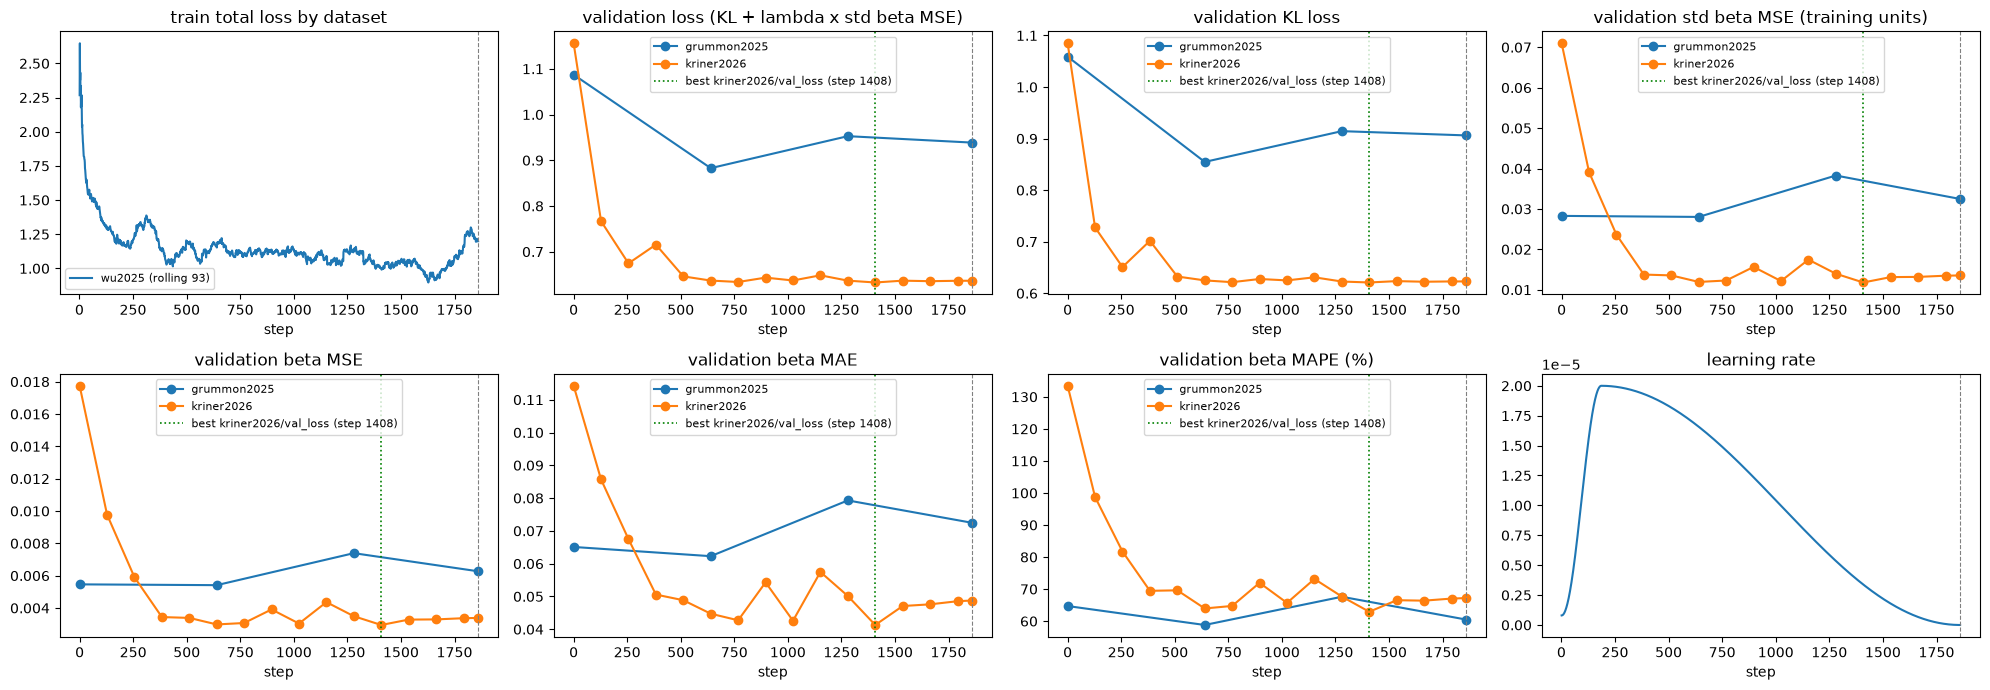

wu2025 | lambda=1:   0%|          | 0/1860 [00:00<?, ?it/s]

pass 1 (forward): 0it [00:00, ?it/s]

Evaluating kriner2026_validation (shared-state):   0%|          | 0/5 [00:00<?, ?batch/s]

Evaluating kriner2026_validation (shared-state):   0%|          | 0/5 [00:00<?, ?batch/s]

Evaluating kriner2026_validation (shared-state):   0%|          | 0/5 [00:00<?, ?batch/s]

Evaluating kriner2026_validation (shared-state):   0%|          | 0/5 [00:00<?, ?batch/s]

... (12 outputs left out)

Evaluating grummon2025_validation (shared-state):   0%|          | 0/35 [00:00<?, ?batch/s]

Evaluating kriner2026_validation (shared-state):   0%|          | 0/5 [00:00<?, ?batch/s]

Evaluating grummon2025_validation (shared-state):   0%|          | 0/35 [00:00<?, ?batch/s]

best.pt (step 1408) validated at the end on: grummon2025


In [14]:
# Run with sample size tasks per step
sample_size = 10
run_config = sample_size_config(sample_size)
run_dir = RUNS_DIR / run_name(run_config)
runs[run_dir.name] = run_training(
    model=kev_model,
    items_by_dataset=unified_items,
    specs_by_dataset=regression_specs_by_dataset,
    validators=validators,
    step0_validation=step0_validation,
    init_snapshot=INIT_TRAINABLE_STATE,
    config=run_config,
    device=device,
    run_dir=run_dir,
    best_metric=BEST_METRIC,
    best_mode=BEST_MODE,
    run_metadata=RUN_METADATA,
    from_scratch=False,   # an existing run is resumed (or loaded, if finished); True deletes it and trains again
)

,epoch,rows_seen,train_loss,grummon2025/val_loss,grummon2025/std_beta_mse,grummon2025/kl_loss,grummon2025/beta_mse,grummon2025/beta_mae,grummon2025/beta_mape_pct,grummon2025/spearman_rho,kriner2026/val_loss,kriner2026/std_beta_mse,kriner2026/kl_loss,kriner2026/beta_mse,kriner2026/beta_mae,kriner2026/beta_mape_pct,kriner2026/spearman_rho,lr,grummon2025/eval_wall_sec,kriner2026/eval_wall_sec,train_elapsed_sec
step,,,,,,,,,,,,,,,,,,,,,
0,0,0,NaN,1.08718,0.02828,1.05890,0.00546,0.06510,64.72026,0.50000,1.15581,0.07099,1.08483,0.01775,0.11425,133.43868,-0.26573,NaN,66.59824,9.43978,0.00000
32,1,1280,0.78897,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.73141,0.03227,0.69914,0.00807,0.07959,96.65491,0.32168,0.00003,NaN,10.21734,25.10900
64,1,2560,0.68235,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.65087,0.01890,0.63197,0.00472,0.06044,76.50731,0.90909,0.00004,NaN,10.22498,50.28831
96,1,3840,0.69197,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.65344,0.02148,0.63196,0.00537,0.06432,79.06460,0.92308,0.00004,NaN,10.17438,75.49435
128,1,5120,0.67720,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.65702,0.02024,0.63678,0.00506,0.06191,74.97385,0.90210,0.00004,NaN,10.07297,100.62068
160,1,6400,0.64766,1.04622,0.06188,0.98434,0.01195,0.10552,88.27644,0.80000,0.65022,0.01793,0.63229,0.00448,0.05903,75.12495,0.85315,0.00003,62.83975,9.94491,125.75882
192,1,7680,0.68330,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.65839,0.02175,0.63664,0.00544,0.06411,77.37302,0.90210,0.00003,NaN,10.05197,150.93630
224,1,8960,0.64110,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.64509,0.01148,0.63361,0.00287,0.04259,64.21671,0.90210,0.00002,NaN,10.06858,176.08307
256,1,10240,0.61770,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.64017,0.01391,0.62626,0.00348,0.04991,68.00894,0.90210,0.00002,NaN,10.05350,201.21728


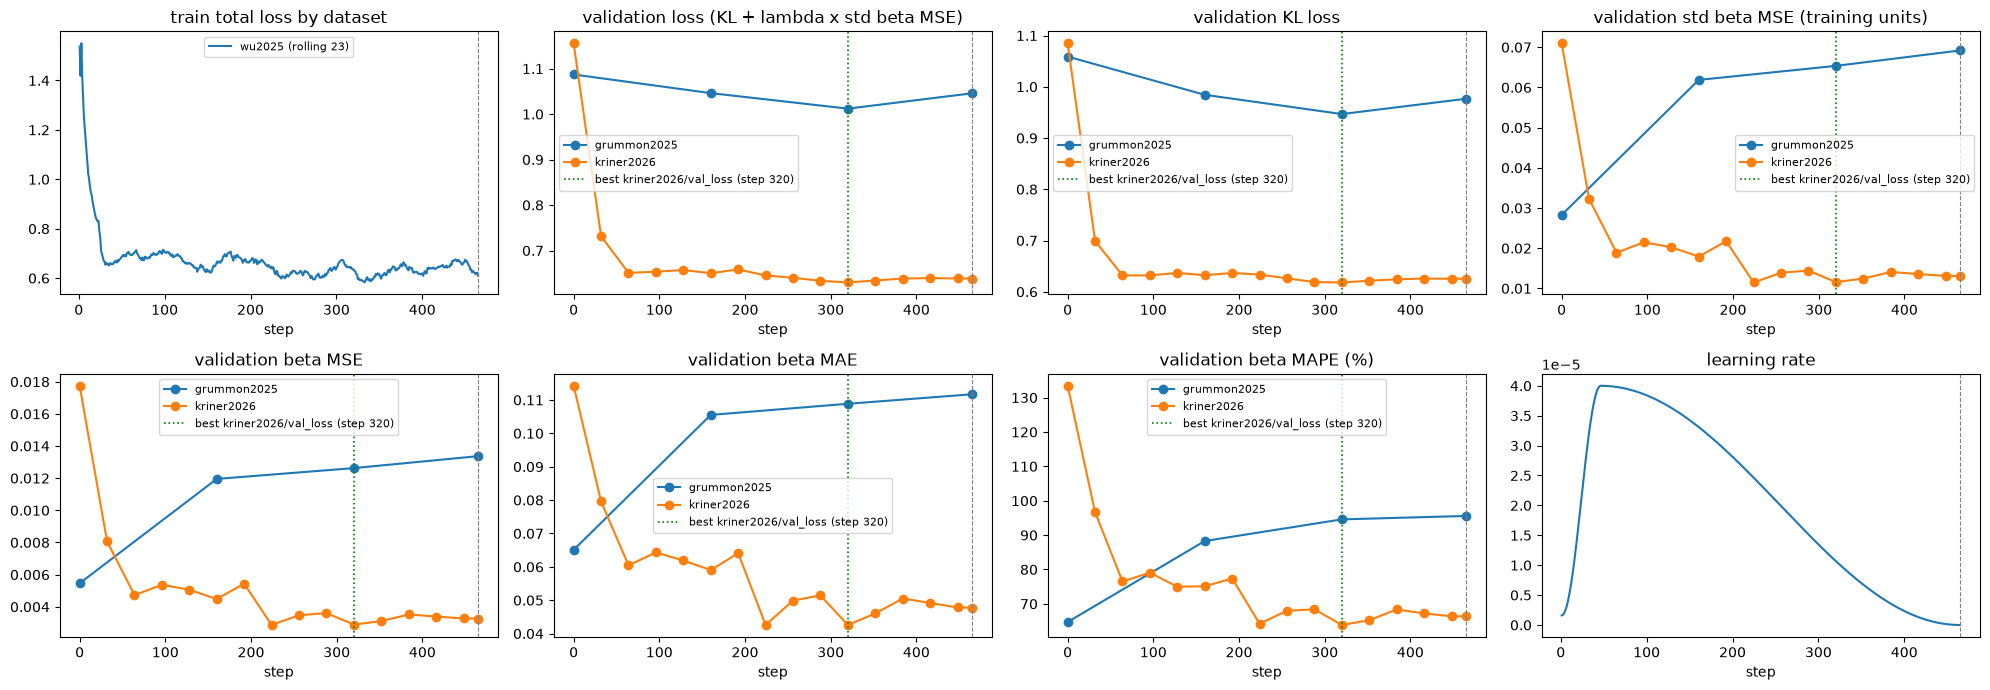

wu2025 | lambda=1:   0%|          | 0/465 [00:00<?, ?it/s]

pass 1 (forward): 0it [00:00, ?it/s]

Evaluating kriner2026_validation (shared-state):   0%|          | 0/5 [00:00<?, ?batch/s]

Evaluating kriner2026_validation (shared-state):   0%|          | 0/5 [00:00<?, ?batch/s]

Evaluating kriner2026_validation (shared-state):   0%|          | 0/5 [00:00<?, ?batch/s]

Evaluating kriner2026_validation (shared-state):   0%|          | 0/5 [00:00<?, ?batch/s]

... (10 outputs left out)

Evaluating kriner2026_validation (shared-state):   0%|          | 0/5 [00:00<?, ?batch/s]

Evaluating kriner2026_validation (shared-state):   0%|          | 0/5 [00:00<?, ?batch/s]

Evaluating grummon2025_validation (shared-state):   0%|          | 0/35 [00:00<?, ?batch/s]

Evaluating kriner2026_validation (shared-state):   0%|          | 0/5 [00:00<?, ?batch/s]

In [13]:
# Run with sample size tasks per step
sample_size = 40
run_config = sample_size_config(sample_size)
run_dir = RUNS_DIR / run_name(run_config)
runs[run_dir.name] = run_training(
    model=kev_model,
    items_by_dataset=unified_items,
    specs_by_dataset=regression_specs_by_dataset,
    validators=validators,
    step0_validation=step0_validation,
    init_snapshot=INIT_TRAINABLE_STATE,
    config=run_config,
    device=device,
    run_dir=run_dir,
    best_metric=BEST_METRIC,
    best_mode=BEST_MODE,
    run_metadata=RUN_METADATA,
    from_scratch=False,   # an existing run is resumed (or loaded, if finished); True deletes it and trains again
)

,epoch,rows_seen,train_loss,grummon2025/val_loss,grummon2025/std_beta_mse,grummon2025/kl_loss,grummon2025/beta_mse,grummon2025/beta_mae,grummon2025/beta_mape_pct,grummon2025/spearman_rho,kriner2026/val_loss,kriner2026/std_beta_mse,kriner2026/kl_loss,kriner2026/beta_mse,kriner2026/beta_mae,kriner2026/beta_mape_pct,kriner2026/spearman_rho,lr,grummon2025/eval_wall_sec,kriner2026/eval_wall_sec,train_elapsed_sec
step,,,,,,,,,,,,,,,,,,,,,
0,0,0,NaN,1.08718,0.02828,1.05890,0.00546,0.06510,64.72026,0.50000,1.15581,0.07099,1.08483,0.01775,0.11425,133.43868,-0.26573,NaN,66.59824,9.43978,0.00000
8,1,1280,0.81448,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.74494,0.04035,0.70460,0.01009,0.08705,100.78202,0.28671,0.00006,NaN,10.18873,26.25398
16,1,2560,0.63517,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.68780,0.02134,0.66646,0.00533,0.06423,78.04674,0.77622,0.00008,NaN,10.49882,52.61309
24,1,3840,0.64791,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.63536,0.01240,0.62296,0.00310,0.04520,69.78297,0.86014,0.00008,NaN,10.43554,78.82868
32,1,5120,0.61513,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.64204,0.01379,0.62825,0.00345,0.04873,72.25537,0.84615,0.00007,NaN,10.30020,105.19109
40,1,6400,0.60689,0.87998,0.03757,0.84241,0.00726,0.07911,74.04149,0.80000,0.64129,0.01318,0.62810,0.00330,0.04719,69.16892,0.83916,0.00007,63.02397,10.17170,131.48995
48,1,7680,0.63338,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.66671,0.02511,0.64160,0.00628,0.06944,83.17322,0.74825,0.00006,NaN,10.25518,157.75488
56,1,8960,0.59438,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.64721,0.01371,0.63350,0.00343,0.04870,69.86192,0.80420,0.00005,NaN,10.24636,184.03580
64,1,10240,0.58443,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.65355,0.01435,0.63920,0.00359,0.05010,69.55542,0.81818,0.00004,NaN,10.38129,210.27357


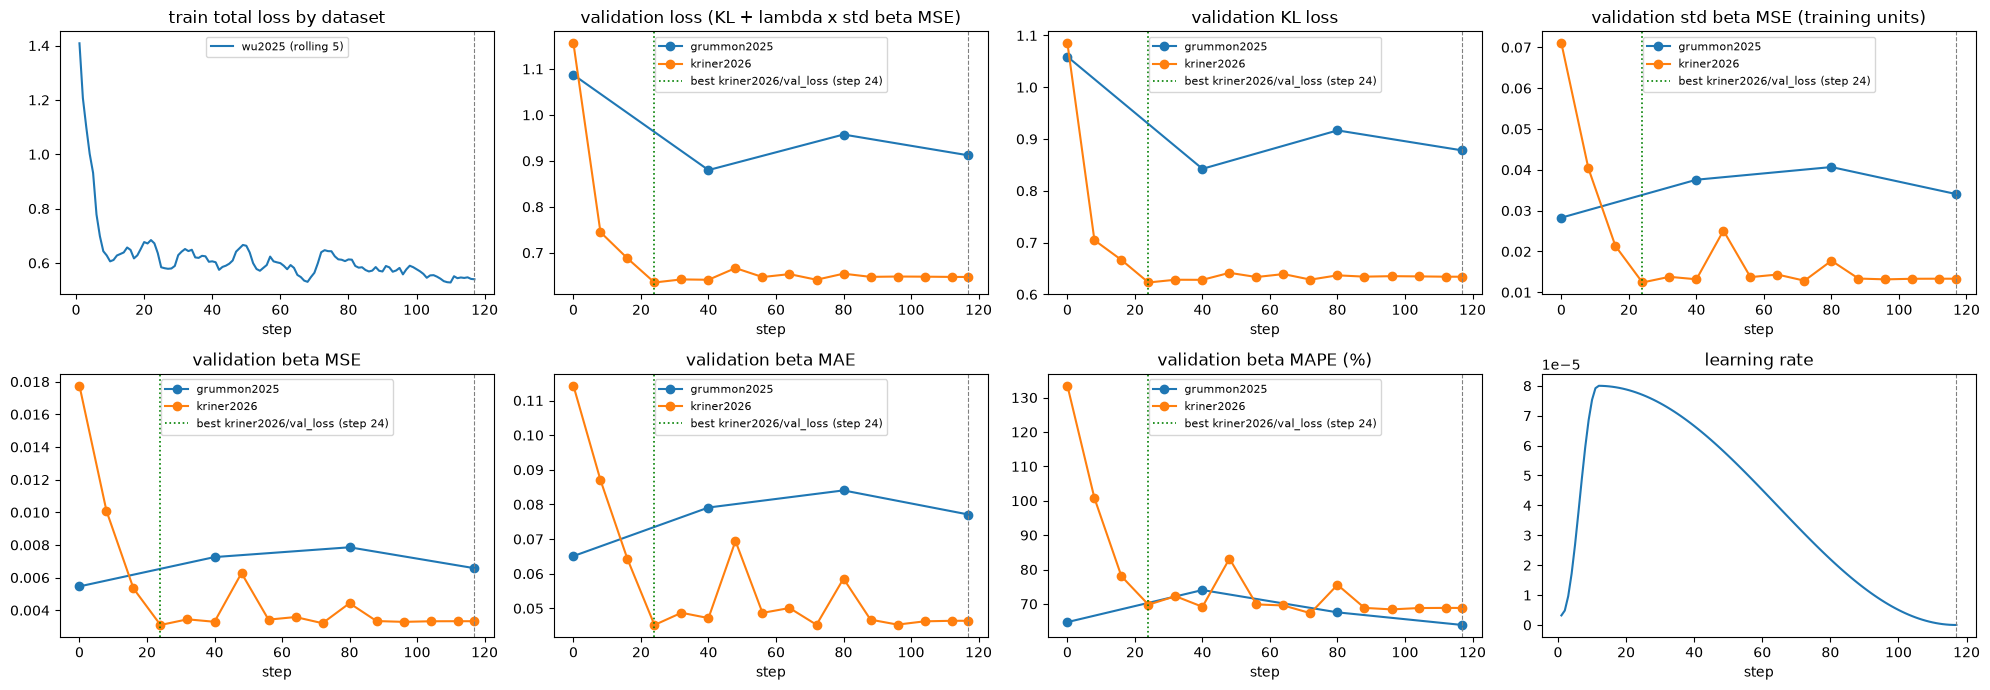

wu2025 | lambda=1:   0%|          | 0/117 [00:00<?, ?it/s]

pass 1 (forward): 0it [00:00, ?it/s]

Evaluating kriner2026_validation (shared-state):   0%|          | 0/5 [00:00<?, ?batch/s]

Evaluating kriner2026_validation (shared-state):   0%|          | 0/5 [00:00<?, ?batch/s]

Evaluating kriner2026_validation (shared-state):   0%|          | 0/5 [00:00<?, ?batch/s]

Evaluating kriner2026_validation (shared-state):   0%|          | 0/5 [00:00<?, ?batch/s]

... (12 outputs left out)

Evaluating grummon2025_validation (shared-state):   0%|          | 0/35 [00:00<?, ?batch/s]

Evaluating kriner2026_validation (shared-state):   0%|          | 0/5 [00:00<?, ?batch/s]

Evaluating grummon2025_validation (shared-state):   0%|          | 0/35 [00:00<?, ?batch/s]

best.pt (step 24) validated at the end on: grummon2025


In [12]:
# Run with sample size 160 tasks per step
sample_size = 160
run_config = sample_size_config(sample_size)
run_dir = RUNS_DIR / run_name(run_config)
runs[run_dir.name] = run_training(
    model=kev_model,
    items_by_dataset=unified_items,
    specs_by_dataset=regression_specs_by_dataset,
    validators=validators,
    step0_validation=step0_validation,
    init_snapshot=INIT_TRAINABLE_STATE,
    config=run_config,
    device=device,
    run_dir=run_dir,
    best_metric=BEST_METRIC,
    best_mode=BEST_MODE,
    run_metadata=RUN_METADATA,
    from_scratch=False,   # an existing run is resumed (or loaded, if finished); True deletes it and trains again
)

,epoch,rows_seen,train_loss,grummon2025/val_loss,grummon2025/std_beta_mse,grummon2025/kl_loss,grummon2025/beta_mse,grummon2025/beta_mae,grummon2025/beta_mape_pct,grummon2025/spearman_rho,kriner2026/val_loss,kriner2026/std_beta_mse,kriner2026/kl_loss,kriner2026/beta_mse,kriner2026/beta_mae,kriner2026/beta_mape_pct,kriner2026/spearman_rho,lr,grummon2025/eval_wall_sec,kriner2026/eval_wall_sec,train_elapsed_sec
step,,,,,,,,,,,,,,,,,,,,,
0,0,0,NaN,1.08718,0.02828,1.05890,0.00546,0.06510,64.72026,0.50000,1.15581,0.07099,1.08483,0.01775,0.11425,133.43868,-0.26573,NaN,66.59824,9.43978,0.00000
2,1,1280,1.08966,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.78462,0.04685,0.73777,0.01171,0.09353,109.11342,0.14685,0.00008,NaN,10.09023,25.90771
4,1,2560,0.83531,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.69748,0.03530,0.66217,0.00883,0.08107,94.16954,0.40559,0.00016,NaN,9.99206,51.32861
6,1,3840,0.78770,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.72099,0.01834,0.70265,0.00458,0.06032,82.39897,0.72028,0.00016,NaN,9.96847,76.77036
8,1,5120,0.73817,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.70583,0.04050,0.66533,0.01012,0.08434,95.36761,0.72727,0.00015,NaN,9.96557,102.12703
10,1,6400,0.68375,0.96289,0.08401,0.87889,0.01623,0.12551,109.53483,0.90000,0.66641,0.01744,0.64897,0.00436,0.05504,81.38614,0.56643,0.00013,63.41917,10.17688,127.53263
12,1,7680,0.59888,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.66729,0.02089,0.64639,0.00522,0.06389,87.04774,0.65035,0.00012,NaN,10.28163,153.02965
14,1,8960,0.66092,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.67287,0.02233,0.65054,0.00558,0.06614,88.60580,0.65035,0.00010,NaN,10.29357,178.42644
16,1,10240,0.57319,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.66574,0.01754,0.64820,0.00438,0.05493,84.55801,0.67133,0.00008,NaN,10.25050,203.87037


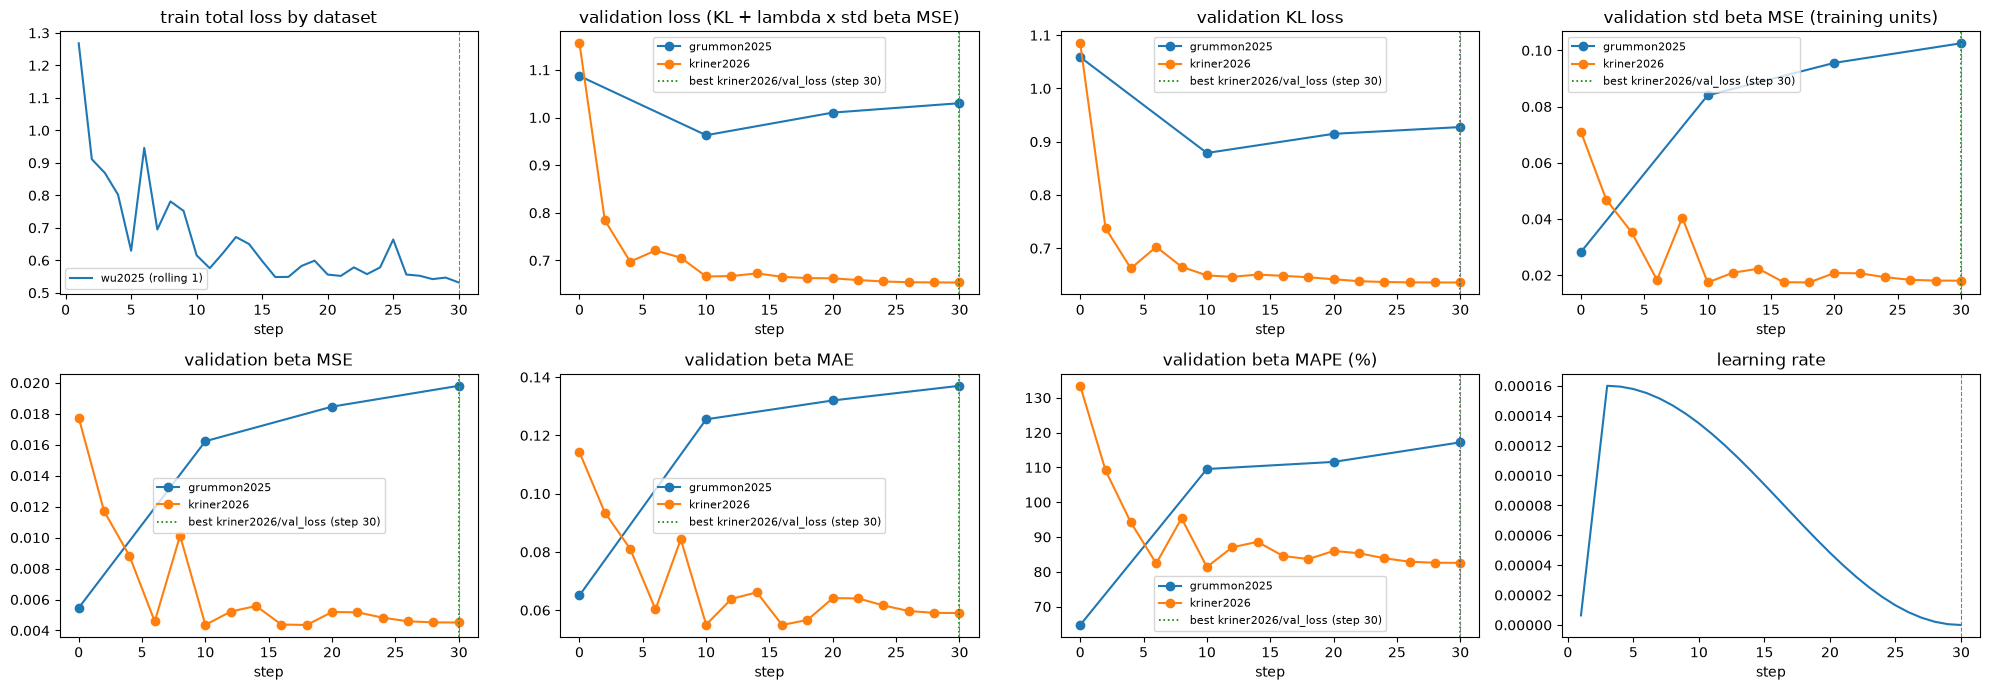

wu2025 | lambda=1:   0%|          | 0/30 [00:00<?, ?it/s]

pass 1 (forward): 0it [00:00, ?it/s]

Evaluating kriner2026_validation (shared-state):   0%|          | 0/5 [00:00<?, ?batch/s]

Evaluating kriner2026_validation (shared-state):   0%|          | 0/5 [00:00<?, ?batch/s]

Evaluating kriner2026_validation (shared-state):   0%|          | 0/5 [00:00<?, ?batch/s]

Evaluating kriner2026_validation (shared-state):   0%|          | 0/5 [00:00<?, ?batch/s]

... (10 outputs left out)

Evaluating kriner2026_validation (shared-state):   0%|          | 0/5 [00:00<?, ?batch/s]

Evaluating kriner2026_validation (shared-state):   0%|          | 0/5 [00:00<?, ?batch/s]

Evaluating grummon2025_validation (shared-state):   0%|          | 0/35 [00:00<?, ?batch/s]

Evaluating kriner2026_validation (shared-state):   0%|          | 0/5 [00:00<?, ?batch/s]

In [11]:
# Sample size 640 tasks per step
sample_size = 640
run_config = sample_size_config(sample_size)
run_dir = RUNS_DIR / run_name(run_config)
runs[run_dir.name] = run_training(
    model=kev_model,
    items_by_dataset=unified_items,
    specs_by_dataset=regression_specs_by_dataset,
    validators=validators,
    step0_validation=step0_validation,
    init_snapshot=INIT_TRAINABLE_STATE,
    config=run_config,
    device=device,
    run_dir=run_dir,
    best_metric=BEST_METRIC,
    best_mode=BEST_MODE,
    run_metadata=RUN_METADATA,
    from_scratch=False,   # an existing run is resumed (or loaded, if finished); True deletes it and trains again
)

In [ ]:
# Sample size 1280 tasks per step
sample_size = 1280
run_config = sample_size_config(sample_size)
run_dir = RUNS_DIR / run_name(run_config)
runs[run_dir.name] = run_training(
    model=kev_model,
    items_by_dataset=unified_items,
    specs_by_dataset=regression_specs_by_dataset,
    validators=validators,
    step0_validation=step0_validation,
    init_snapshot=INIT_TRAINABLE_STATE,
    config=run_config,
    device=device,
    run_dir=run_dir,
    best_metric=BEST_METRIC,
    best_mode=BEST_MODE,
    run_metadata=RUN_METADATA,
    from_scratch=False,   # an existing run is resumed (or loaded, if finished); True deletes it and trains again
)

In [ ]:
# Sample size 2560 tasks per step
sample_size = 2560
run_config = sample_size_config(sample_size)
run_dir = RUNS_DIR / run_name(run_config)
runs[run_dir.name] = run_training(
    model=kev_model,
    items_by_dataset=unified_items,
    specs_by_dataset=regression_specs_by_dataset,
    validators=validators,
    step0_validation=step0_validation,
    init_snapshot=INIT_TRAINABLE_STATE,
    config=run_config,
    device=device,
    run_dir=run_dir,
    best_metric=BEST_METRIC,
    best_mode=BEST_MODE,
    run_metadata=RUN_METADATA,
    from_scratch=False,   # an existing run is resumed (or loaded, if finished); True deletes it and trains again
)

In [ ]:
# Compare finished runs: final validation metrics, per-dataset train losses, and each validator's betas
display(comparison_table(runs, step0_validation).round(5))
display(per_dataset_table(runs).round(5))
for dataset_name in validators:
    display(eval_beta_table(runs, step0_validation, dataset_name).round(4))

# The same runs at their best validation (by each run's best metric)
display(best_table(runs).round(5))
for dataset_name in validators:
    display(best_beta_table(runs, step0_validation, dataset_name).round(4))

In [ ]:
# Load every saved run of this notebook from disk (no training; works in a fresh kernel after the setup cells)
runs = {}
for saved_run_dir in sorted(RUNS_DIR.iterdir()):
    runs[saved_run_dir.name] = load_run(saved_run_dir)
display(pd.DataFrame([run.summary for run in runs.values()]).set_index("label"))

In [ ]:
# Put one run's best checkpoint into kev_model (e.g. to evaluate it further)
BEST_RUN_DIR = RUNS_DIR / run_name(sample_size_config(BASE_SAMPLE_SIZE))
best_checkpoint = load_best(BEST_RUN_DIR)
reset_trainable(kev_model, best_checkpoint["trainable"])
display(pd.Series(best_checkpoint["best"], name=BEST_RUN_DIR.name).to_frame())

In [ ]:
# Decompose each validator's beta MSE into per-beta squared errors across runs
for dataset_name in validators:
    display(mse_decomposition(runs, step0_validation, dataset_name).round(5))

# Cross-dataset beta scale and sample-size target noise

In [ ]:
# Compare raw vs sigma_y-standardized human beta mean-square across the loaded datasets
scale_rows = []
for dataset_name, tidy in human_ols_by_dataset.items():
    choice_df = choice_dfs[dataset_name]
    option_counts = sorted({len(one_hot) for one_hot in choice_df["one_hot"]})
    sigma_by_model = tidy.groupby("model", sort=False)["sigma_y"].first()
    scale_rows.append(
        {
            "dataset": dataset_name,
            "respondents": choice_df["CASEID"].nunique(),
            "tasks": len(choice_df),
            "options_per_task": ", ".join(str(n) for n in option_counts),
            "regressions": len(sigma_by_model),
            "num_betas": len(tidy),
            "sigma_y": ", ".join(f"{sigma:.4g}" for sigma in sigma_by_model),
            "raw_signal_beta_ms": float((tidy["human_beta"] ** 2).mean()),
            "std_signal_beta_ms": float((tidy["std_beta"] ** 2).mean()),
        }
    )
display(pd.DataFrame(scale_rows).set_index("dataset").round(5))

# Rank deficiency

In [ ]:
# Target noise of sample betas vs row sample size (Monte Carlo over data rows = training items), per regression
for SNR_DATASET in TRAIN_DATASETS:  
    SNR_SAMPLE_SIZES = [16, 32, 64, 128, 256]
    SNR_DRAWS = 4000

    beta_noise_df = beta_core.beta_noise_by_sample_size(
        regression_rows_by_dataset[SNR_DATASET],
        regression_specs_by_dataset[SNR_DATASET],
        SNR_SAMPLE_SIZES,
        SNR_DRAWS,
        seed=42,
    )
    display(beta_noise_df.set_index(["model", "sample_size"]).round(4))

# Test micro-batching

In [ ]:
# Two-pass micro-chunked gradient (training) vs one backward through the whole sample
CHECK_DATASET = "grummon2023"   # any key of `unified_items`
CHECK_SAMPLE_SIZE = 15          # one graph of this many items (rows) must fit in VRAM (method A)
CHECK_MICRO_CHUNK = 3           # items (data rows) per chunk
CHECK_BETA_LAMBDA = 5.0         # > 0 so both KL and beta gradients are tested

gradient_check_result = gradient_check(
    kev_model,
    unified_items[CHECK_DATASET],
    regression_specs_by_dataset[CHECK_DATASET],
    INIT_TRAINABLE_STATE,
    sample_size=CHECK_SAMPLE_SIZE,
    micro_chunk=CHECK_MICRO_CHUNK,
    beta_lambda=CHECK_BETA_LAMBDA,
    seed=0,
    device=device,
)
display(pd.Series(gradient_check_result, name="gradient_check").to_frame())

# Overfit first

In [ ]:
# Overfit sanity check: many passes with pure KL/CE, constant LR, and zero weight decay
BASE_LR_SAMPLE_1 = 2e-5   # validated 1-respondent/step LR; scaled by sqrt(sample size)

OVERFIT_CONFIG = TrainConfig(
    train_datasets=("grummon2023",),
    sample_size_by_dataset={"grummon2023": 128},
    beta_lambda=0.0,
    lr=scale_lr_for_sample_size(BASE_LR_SAMPLE_1, 128),
    num_epochs=10,
    eval_every_by_validator={name: math.ceil(len(unified_items["grummon2023"]) / 128) for name in VALIDATION_DATASETS},   # one validation per epoch
    lr_schedule="constant",
    weight_decay=0.0,
    micro_chunk=MAX_FITTING_MICRO_CHUNK,
    gradient_checkpointing=SEARCH_GRADIENT_CHECKPOINTING,
    grad_clip=1.0,
    seed=42,
)
overfit_run = run_training(
    model=kev_model,
    items_by_dataset=unified_items,
    specs_by_dataset=regression_specs_by_dataset,
    validators=validators,
    step0_validation=step0_validation,
    init_snapshot=INIT_TRAINABLE_STATE,
    config=OVERFIT_CONFIG,
    device=device,
    run_dir=RUNS_DIR / f"overfit_{run_name(OVERFIT_CONFIG)}",
    best_metric=BEST_METRIC,
    best_mode=BEST_MODE,
    run_metadata=RUN_METADATA,
    from_scratch=False,   # an existing run is resumed (or loaded, if finished); True deletes it and trains again
)